# T16e: coverage-context ML features

Companion notebook to `README.md` in this folder. Running top-to-bottom regenerates every figure in `figures/` from the saved results in `data/` (or the referenced `runs/` directory).

In [1]:
# Setup: make the flat claude_files package importable and load shared helpers.
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-10-15_t16e-coverage-features"
FIG = REPORT / "figures"
DATA = REPORT / "data"
FIG.mkdir(exist_ok=True)

import evaluation as ev  # project-wide scoring convention (REL_TOL, outcome categories)


## Load results

The labelled candidate table (`data/candidates.csv.gz`, slim copy of `runs/t16e_features/candidates.pkl` written by `build_feature_tables.py`) and the tables `analysis.py` computed from it. The interaction check (~3 min of bootstrapping) is read from `data/interaction.csv`; rerun `analysis.py` to recompute it.

In [2]:
sys.path.insert(0, str(REPO / 'reports' / '2026-10-15_t16e-coverage-features'))
import analysis as A
import warnings; warnings.simplefilter('ignore')
pd.set_option('display.width', 200)
df = A.load()
D = A.DATA
outcomes = pd.read_csv(D / 'outcome_counts.csv')
auc_df = pd.read_csv(D / 'auc_by_coverage.csv')
top_auc = pd.read_csv(D / 'auc_top_candidate.csv')
inter = pd.read_csv(D / 'interaction.csv')
cost = pd.read_csv(D / 'feature_cost.csv')
print(df.shape)
outcomes.round(3)

(18618, 52)


,coverage_spec,n_stars,n_candidates,cand_success,cand_alias,cand_wrong,stars_with_success_candidate,final_success,final_alias,final_wrong,final_none,single_sector_star_frac
0,full,200,4016,0.136,0.125,0.739,0.860,0.730,0.000,0.000,0.270,0.000
1,3-5,200,3163,0.158,0.132,0.710,0.775,0.480,0.000,0.000,0.520,0.000
2,consecutive-2,200,3115,0.117,0.129,0.753,0.695,0.420,0.015,0.020,0.545,0.000
3,gapped-2,200,2725,0.150,0.135,0.714,0.590,0.345,0.005,0.010,0.640,0.000
4,single,200,2688,0.109,0.120,0.770,0.565,0.325,0.005,0.010,0.660,1.000
5,real-weighted,200,2911,0.120,0.122,0.758,0.600,0.370,0.000,0.005,0.625,0.605


## Feature cost

In [3]:
cost.round(3)

,coverage_spec,n_stars,n_candidates,coverage_us_per_candidate,coverage_us_per_star,all_features_ms_per_candidate
0,full,200,4016,38.754,778.186,7.298
1,3-5,200,3163,36.225,572.896,5.710
2,consecutive-2,200,3115,38.249,595.730,5.217
3,gapped-2,200,2725,43.409,591.449,6.543
4,single,200,2688,33.774,453.923,3.695
5,real-weighted,200,2911,35.871,522.108,4.730
6,all,1200,18618,37.752,585.715,5.648


## AUC by coverage (success vs not, candidate level)

Recompute from the candidate table and check it matches the saved CSV, then show the pivot.

In [4]:
recomputed = A.auc_by_coverage(df)
assert np.allclose(recomputed['auc_success_vs_rest'], auc_df['auc_success_vs_rest'], equal_nan=True)
cols = A.SPECS + ['single-sector stars (any spec)', 'all']
auc_df.pivot(index='feature', columns='coverage_spec', values='auc_success_vs_rest')[cols].round(2)

coverage_spec,full,3-5,consecutive-2,gapped-2,single,real-weighted,single-sector stars (any spec),all
feature,,,,,,,,
P_over_lc_baseline,0.26,0.44,0.45,0.49,0.51,0.46,0.53,0.41
P_over_longest_segment,0.26,0.47,0.45,0.50,0.51,0.46,0.53,0.43
acf_half_lag_contrast,0.80,0.82,0.75,0.83,0.75,0.80,0.75,0.80
acf_height_at_P,0.72,0.72,0.67,0.73,0.67,0.68,0.66,0.70
acf_odd_even_contrast,0.62,0.60,0.56,0.57,0.55,0.54,0.54,0.58
duty_cycle,0.50,0.45,0.51,0.48,0.49,0.47,0.49,0.45
few_peaks,0.43,0.51,0.50,0.49,0.48,0.48,0.48,0.48
fold_half_corr,0.21,0.20,0.24,0.20,0.25,0.22,0.25,0.22
fold_half_corr_at_2P,0.82,0.84,0.79,0.85,0.79,0.81,0.78,0.82


Within-star AUC (candidate-level features only; star-level features are constant within a star).

In [5]:
auc_df.pivot(index='feature', columns='coverage_spec', values='auc_within_star')[cols].dropna(how='all').round(2)

coverage_spec,full,3-5,consecutive-2,gapped-2,single,real-weighted,single-sector stars (any spec),all
feature,,,,,,,,
P_over_lc_baseline,0.28,0.48,0.53,0.54,0.58,0.50,0.58,0.47
P_over_longest_segment,0.28,0.48,0.53,0.54,0.58,0.50,0.58,0.47
acf_half_lag_contrast,0.84,0.79,0.74,0.79,0.75,0.76,0.73,0.78
acf_height_at_P,0.81,0.76,0.73,0.74,0.73,0.73,0.71,0.75
acf_odd_even_contrast,0.59,0.60,0.56,0.55,0.54,0.53,0.54,0.57
few_peaks,0.43,0.53,0.53,0.51,0.49,0.51,0.50,0.50
fold_half_corr,0.28,0.27,0.28,0.32,0.32,0.30,0.32,0.29
fold_half_corr_at_2P,0.82,0.79,0.75,0.77,0.76,0.76,0.74,0.78
frac_positive_heights,0.72,0.67,0.68,0.66,0.65,0.67,0.65,0.68


Top-ranked candidate (one row per star, including declined stars): does the feature predict whether it is a success?

In [6]:
top_auc.pivot(index='feature', columns='coverage_spec', values='auc_top_success')[A.SPECS + ['all']].round(2)

coverage_spec,full,3-5,consecutive-2,gapped-2,single,real-weighted,all
feature,,,,,,,
P_over_lc_baseline,0.55,0.67,0.74,0.68,0.75,0.60,0.61
P_over_longest_segment,0.55,0.67,0.74,0.70,0.75,0.62,0.62
acf_half_lag_contrast,0.99,0.96,0.96,0.95,0.96,0.97,0.96
acf_height_at_P,0.97,0.81,0.88,0.76,0.83,0.85,0.83
acf_odd_even_contrast,0.60,0.49,0.46,0.41,0.46,0.45,0.47
duty_cycle,0.50,0.52,0.54,0.49,0.48,0.40,0.43
few_peaks,0.48,0.53,0.55,0.56,0.57,0.54,0.53
fold_half_corr,0.12,0.11,0.07,0.10,0.05,0.08,0.09
fold_half_corr_at_2P,0.96,0.94,0.94,0.95,0.95,0.95,0.94


## Interaction check

In [7]:
inter[inter.metric != 'top1_all'].round(3)

,train,evaluate,model,metric,value,delta_vs_existing,delta_lo90,delta_hi90,n_stars,n_candidates,pipeline_final_success
0,trained on all,all stars,existing,cand_auc,0.901,0.000,0.000,0.000,1200,18618,0.445
1,trained on all,all stars,existing,top1_recov,0.754,0.000,0.000,0.000,1200,18618,0.445
3,trained on all,all stars,existing,conf_auc,0.966,0.000,0.000,0.000,1200,18618,0.445
4,trained on all,all stars,+coverage,cand_auc,0.902,0.000,-0.001,0.002,1200,18618,0.445
5,trained on all,all stars,+coverage,top1_recov,0.749,-0.005,-0.014,0.001,1200,18618,0.445
7,trained on all,all stars,+coverage,conf_auc,0.970,0.004,-0.001,0.011,1200,18618,0.445
8,trained on all,all stars,+coverage+interactions,cand_auc,0.916,0.014,0.007,0.021,1200,18618,0.445
9,trained on all,all stars,+coverage+interactions,top1_recov,0.772,0.018,-0.006,0.050,1200,18618,0.445
11,trained on all,all stars,+coverage+interactions,conf_auc,0.962,-0.004,-0.023,0.016,1200,18618,0.445
12,trained on all,single-sector stars,existing,cand_auc,0.870,0.000,0.000,0.000,321,4309,0.302


## Figures

Regenerate every README figure from the tables above.

fig_auc_heatmap


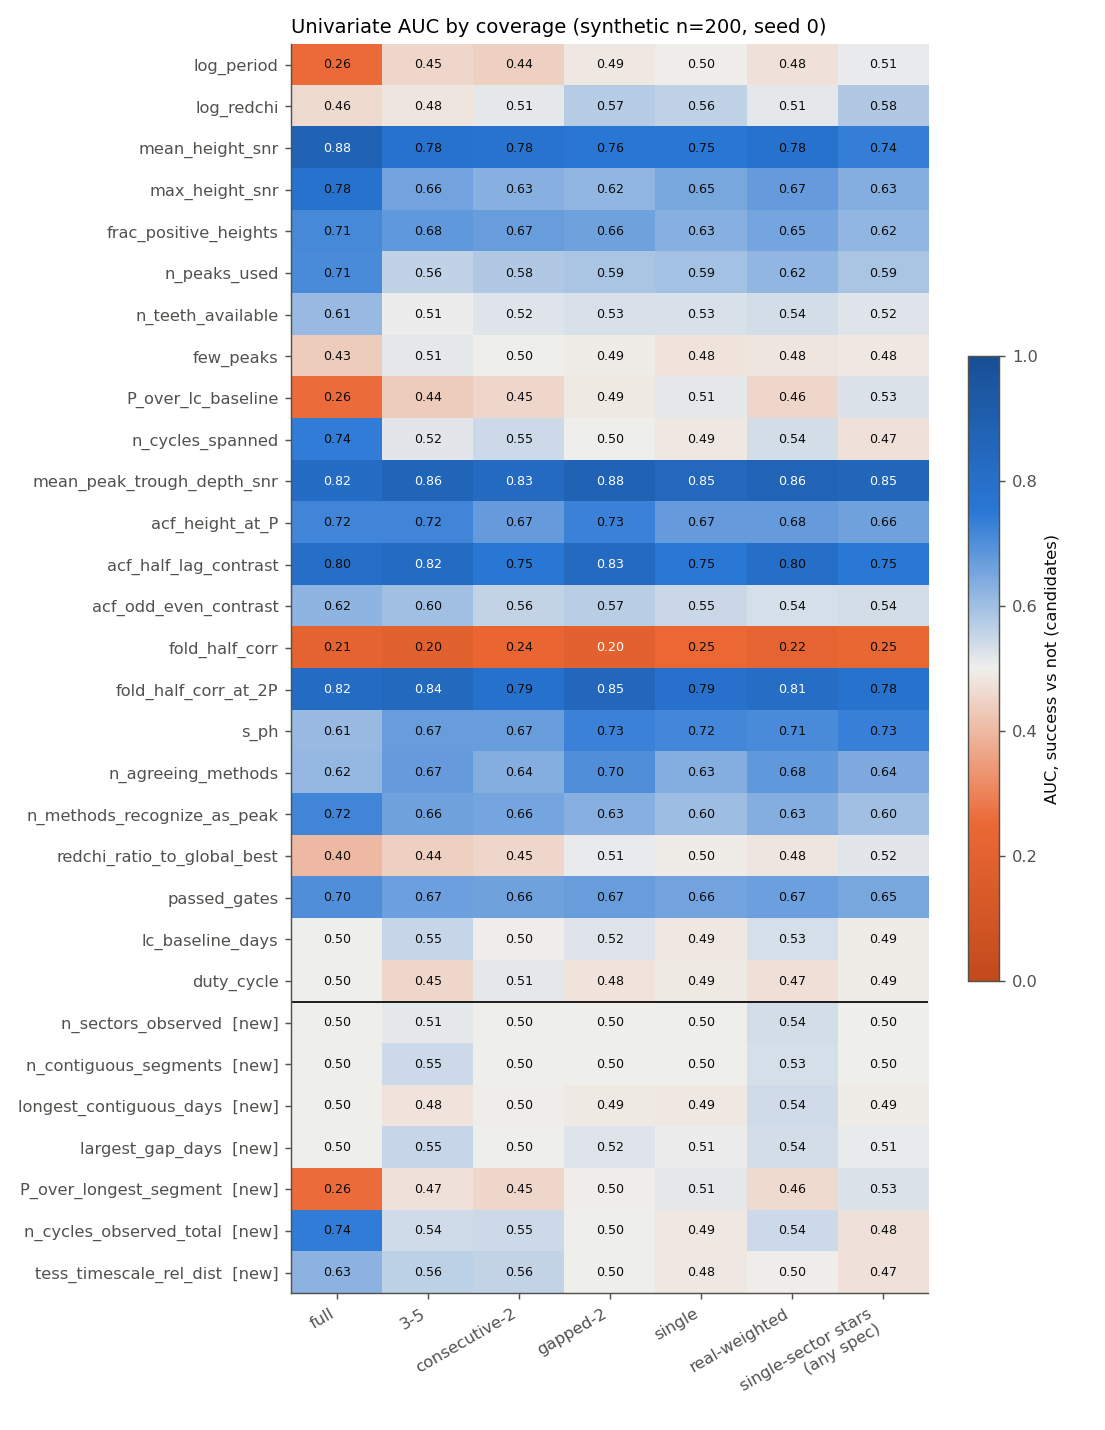

fig_auc_shift


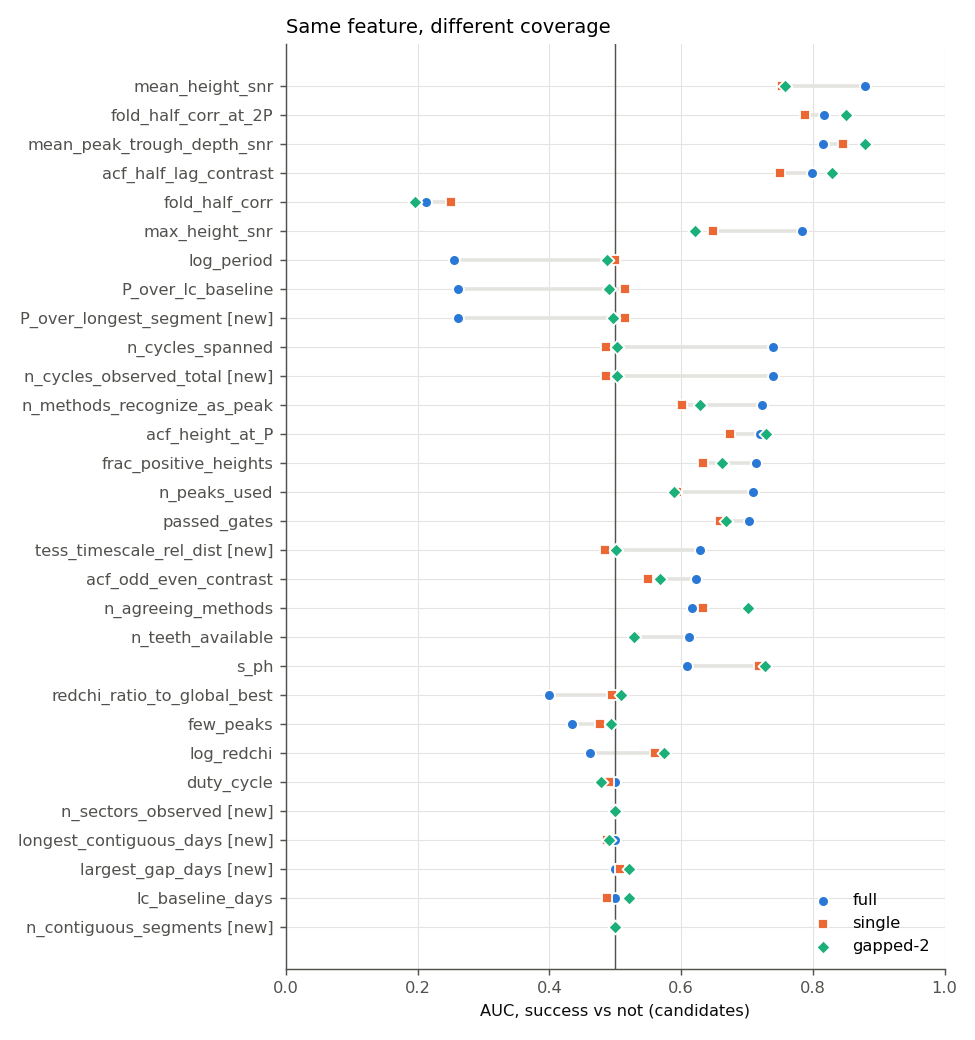

fig_dist_existing


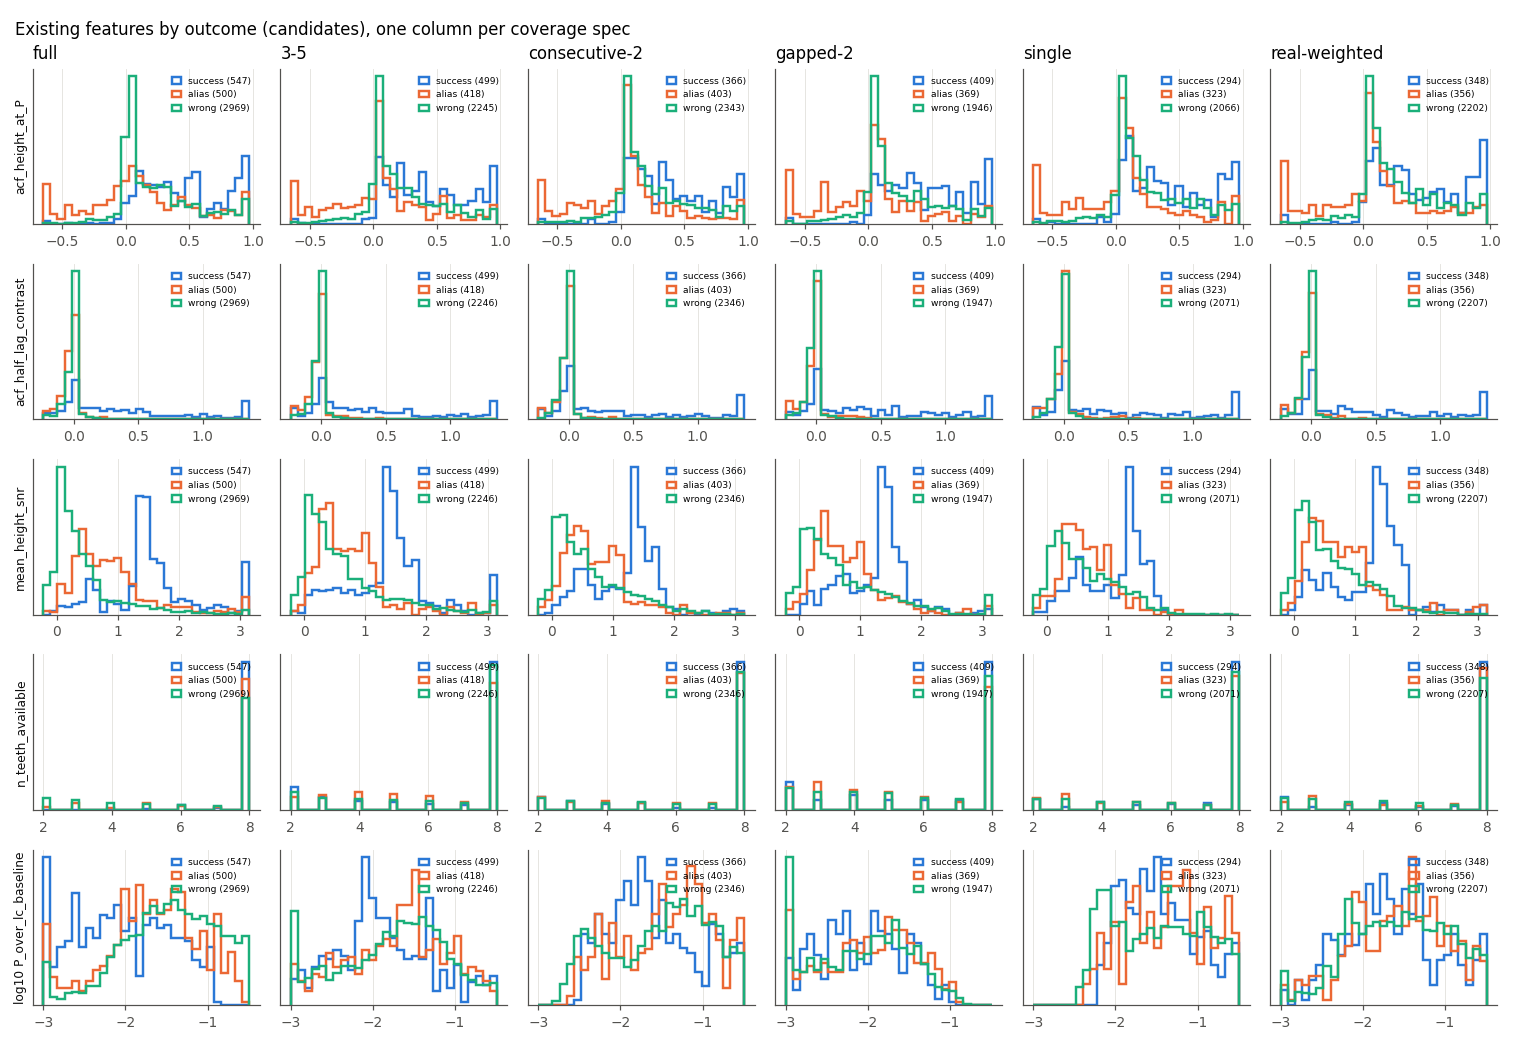

fig_dist_new


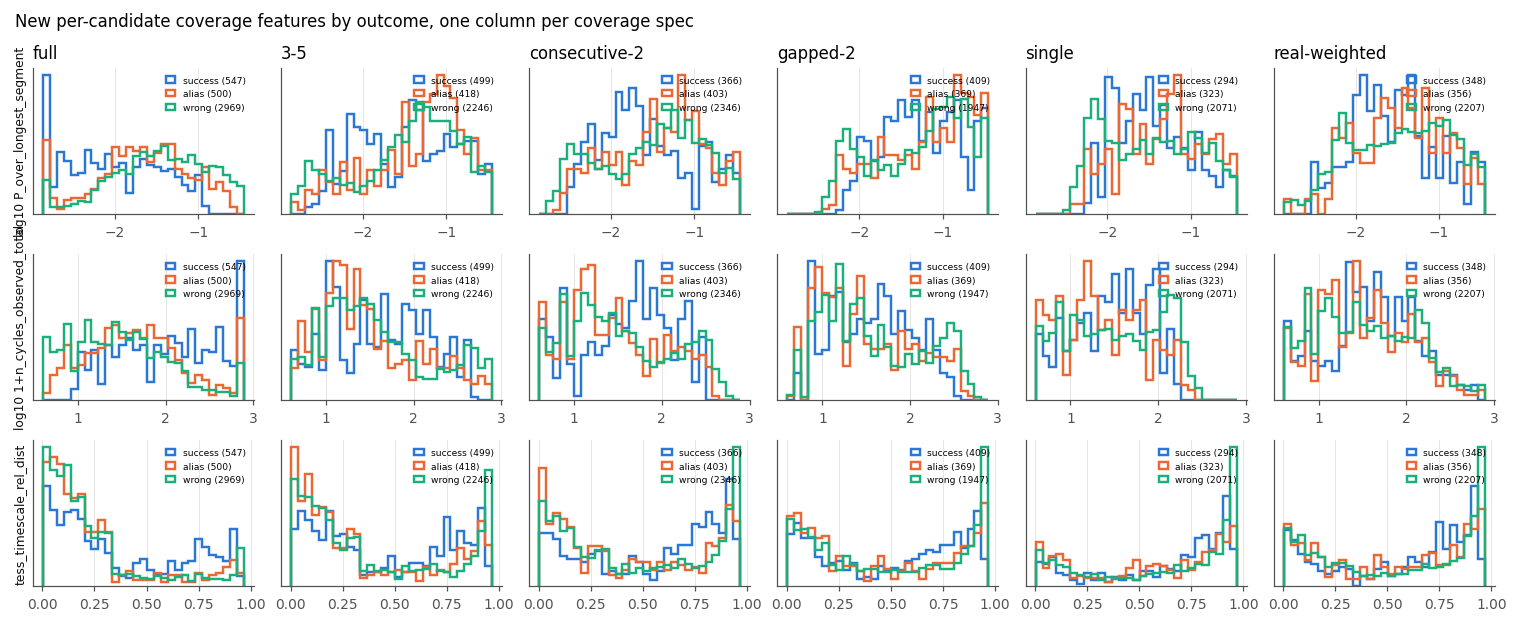

fig_top_candidate


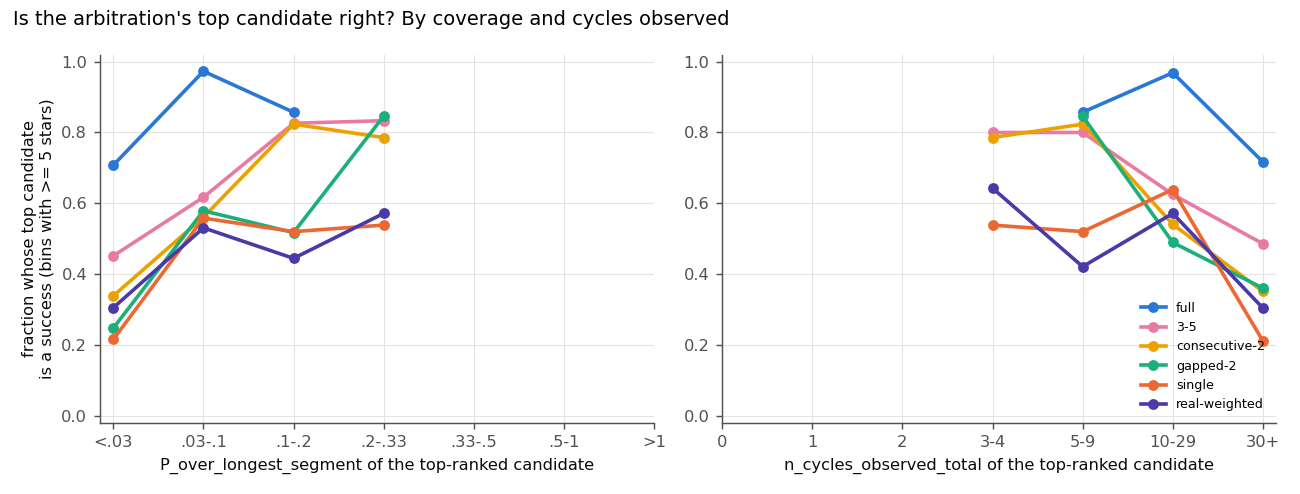

fig_tess_timescale


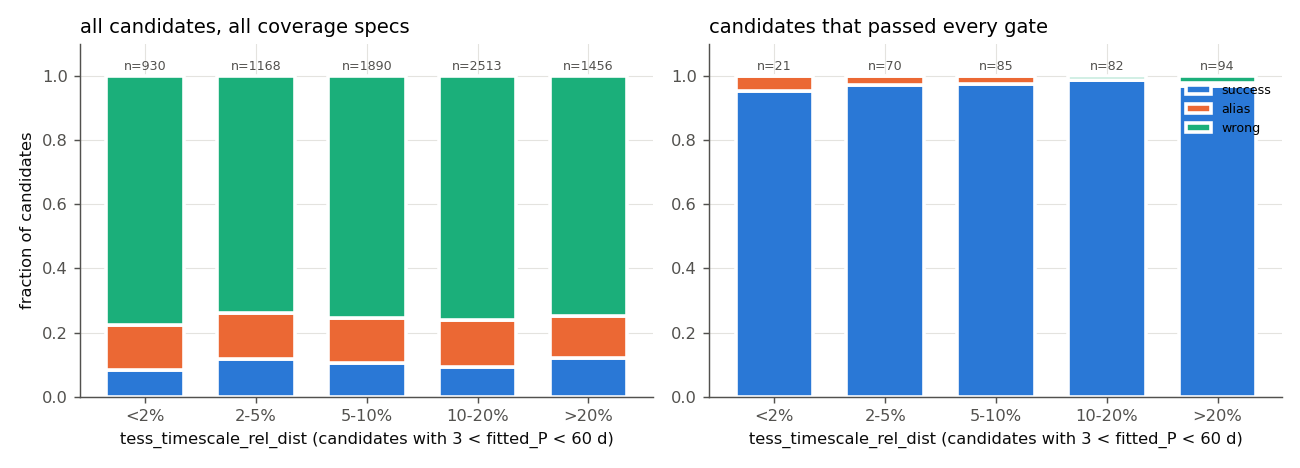

fig_interaction


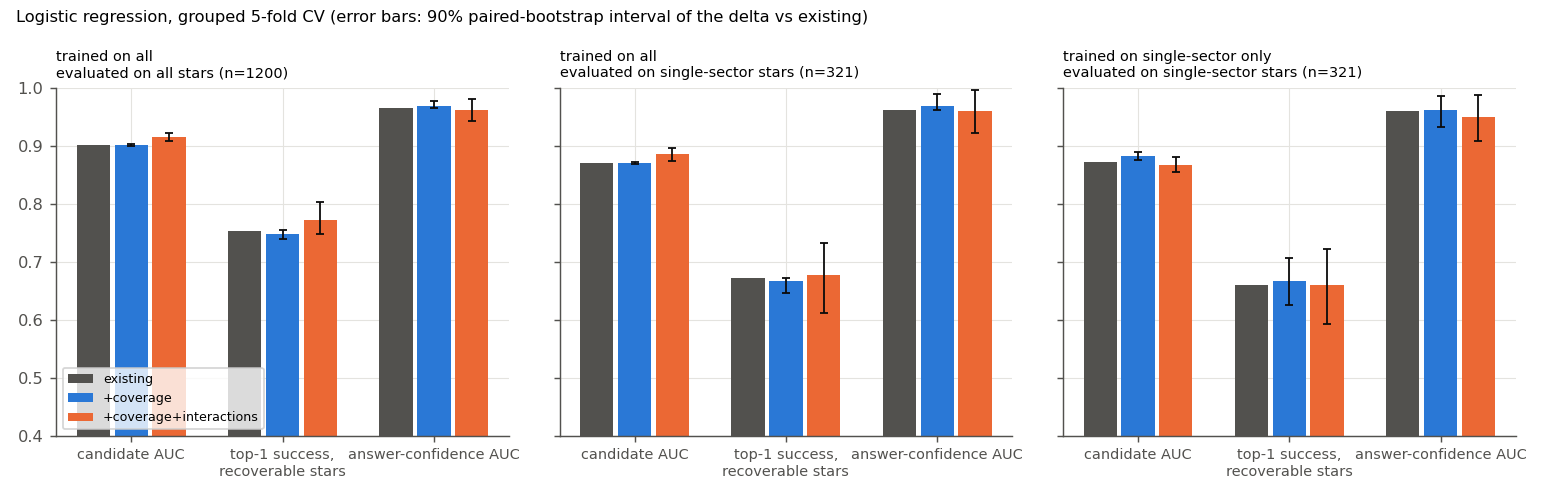

In [8]:
A.make_figures(df, auc_df, inter)
from IPython.display import Image, display
for f in ['fig_auc_heatmap', 'fig_auc_shift', 'fig_dist_existing', 'fig_dist_new', 'fig_top_candidate',
          'fig_tess_timescale', 'fig_interaction']:
    print(f); display(Image(filename=str(A.FIGS / f'{f}.png')))

## Remaining wrong / alias final answers

The pipeline's few wrong answers across all coverage specs: mostly ~0.2 d noise combs with many cycles observed and a tiny (but all-terms-positive) half-lag contrast; the coverage features do not flag them.

In [9]:
st = df[df.cand_index == 0]
st[st.final_outcome.isin(['wrong', 'half', 'double'])][['coverage_spec', 'star_id', 'pattern', 'true_period', 'snr',
    'fitted_P', 'final_outcome', 'tess_timescale_rel_dist', 'P_over_longest_segment', 'n_cycles_observed_total',
    'acf_half_lag_contrast']].round(3)

,coverage_spec,star_id,pattern,true_period,snr,fitted_P,final_outcome,tess_timescale_rel_dist,P_over_longest_segment,n_cycles_observed_total,acf_half_lag_contrast
4131,single,synth-s0-00009,5,0.819,5.025,0.471,half,0.862,0.018,55,0.476
5936,single,synth-s0-00146,13,1.028,4.060,0.188,wrong,0.945,0.007,139,0.052
6273,single,synth-s0-00167,7,38.132,2.429,0.229,wrong,0.933,0.009,115,0.010
7044,consecutive-2,synth-s0-00022,11-12,12.548,4.282,0.250,wrong,0.927,0.005,215,0.017
7434,consecutive-2,synth-s0-00047,10-11,1.067,4.581,0.641,half,0.813,0.012,83,0.020
7702,consecutive-2,synth-s0-00064,2-3,37.471,3.471,0.209,wrong,0.939,0.004,257,0.006
7786,consecutive-2,synth-s0-00070,11-12,0.298,3.117,0.172,half,0.950,0.003,313,0.029
8141,consecutive-2,synth-s0-00096,12-13,13.935,2.077,0.485,wrong,0.858,0.009,110,0.013
8555,consecutive-2,synth-s0-00121,4-5,24.305,3.474,0.193,wrong,0.944,0.004,278,0.015
9615,consecutive-2,synth-s0-00187,7-8,0.334,1.374,0.151,half,0.956,0.003,355,0.029


## TESS-timescale candidates

Candidates within 3% of the 13.7 d ladder vs the rest (3 < fitted_P < 60 d).

In [10]:
d = df[(df.fitted_P > 3) & (df.fitted_P < 60)]
rows = []
for name, s in [('all candidates', d), ('passed every gate', d[d.passed_gates == 1])]:
    near = s.tess_timescale_rel_dist < 0.03
    for lab, m in [('within 3%', near), ('farther', ~near)]:
        rows.append(dict(subset=name, ladder=lab, n=int(m.sum()), success=s[m].success.mean(), alias=s[m].alias.mean(), wrong=s[m].wrong.mean()))
pd.DataFrame(rows).round(3)

,subset,ladder,n,success,alias,wrong
0,all candidates,within 3%,1338,0.091,0.146,0.762
1,all candidates,farther,6619,0.106,0.140,0.754
2,passed every gate,within 3%,39,0.949,0.051,0.000
3,passed every gate,farther,313,0.978,0.013,0.010
